# Tech Challenge — Base de IA para Suporte ao Diagnóstico

**Problema.** Um hospital universitário quer um sistema de IA que acelere a triagem inicial de pacientes e apoie as equipes clínicas. Nesta fase, construímos a base em **Machine Learning**: um modelo de **classificação binária** que estima a probabilidade de um estudante apresentar **depressão**, a partir de dados de estilo de vida (idade, gênero, curso, desempenho acadêmico, sono, estudo, redes sociais, atividade física e estresse).

**Dataset.** `dataset_estilo_de_vida_estudantes.csv` — 100.000 registros brutos sobre estilo de vida de estudantes, com a coluna-alvo `Depression`.

**Roteiro do notebook**
1. Carregamento dos dados
2. Exploração (estatísticas descritivas, distribuições, correlação)
3. Limpeza dos dados
4. Pré-processamento (pipeline sem vazamento de dados) e divisão treino/validação/teste
5. Modelagem (Regressão Logística, Árvore de Decisão e KNN) com busca de hiperparâmetros
6. Treinamento e avaliação (accuracy, recall, F1, ROC-AUC)
7. Interpretação (feature importance e SHAP)
8. Conclusão e discussão crítica

## 1. Imports e reprodutibilidade

Toda a análise usa `random_state`/seeds fixas para que os resultados sejam reproduzíveis. Registramos as versões dos pacotes para auditoria.

In [1]:
import importlib.metadata
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, classification_report, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')

print('Python', sys.version.split()[0])
for pkg in ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'seaborn', 'shap']:
    print(f'{pkg}: {importlib.metadata.version(pkg)}')

Python 3.14.8
pandas: 3.0.6
numpy: 2.5.3
scikit-learn: 1.9.1
matplotlib: 3.11.2
seaborn: 0.13.2
shap: 0.52.0


## 2. Carregamento dos dados

Carregamos a base bruta em um `pandas.DataFrame` e inspecionamos formato, tipos e primeiras linhas.

In [2]:
df = pd.read_csv('dataset.csv')
df.head()

,Student_ID,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
0,1001,22,Female,Science,3.50,7.3,3.3,3.4,114,5,False
1,1002,20,Male,Engineering,2.72,5.5,7.2,6.0,142,2,False
2,1003,20,Male,Medical,3.01,5.4,2.3,1.8,137,3,False
3,1004,21,Male,Engineering,3.63,8.1,2.0,4.6,130,3,False
4,1005,19,Male,Arts,3.14,6.8,2.6,4.3,4,6,False


In [3]:
print('Formato:', df.shape)
print()
df.info()

Formato: (100000, 11)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Student_ID          100000 non-null  int64  
 1   Age                 100000 non-null  int64  
 2   Gender              100000 non-null  str    
 3   Department          100000 non-null  str    
 4   CGPA                100000 non-null  float64
 5   Sleep_Duration      100000 non-null  float64
 6   Study_Hours         100000 non-null  float64
 7   Social_Media_Hours  100000 non-null  float64
 8   Physical_Activity   100000 non-null  int64  
 9   Stress_Level        100000 non-null  int64  
 10  Depression          100000 non-null  bool   
dtypes: bool(1), float64(4), int64(4), str(2)
memory usage: 7.7 MB


As colunas representam:

|Coluna              |Descrição                                                               |
|--------------------|------------------------------------------------------------------------|
|`Student_ID`        |ID do estudante (irrelevante para nosso estudo)                         |
|`Age`               |idade                                                                   |
|`Gender`            |gênero                                                                  |
|`Department`        |departamento dentro da faculdade / universidade                         |
|`CGPA`              |sigla de "Cumulative Grade Point Average", ou seja, nota média acumulada|
|`Sleep_Duration`    |tempo de sono                                                           |
|`Study_Hours`       |horas de estudo                                                         |
|`Social_Media_Hours`|horas de mídia social (uso por dia)                                     |
|`Physical_Activity` |atividade física                                                        |
|`Stress_Level`      |nível de estresse                                                       |
|`Depression`        |depressão                                                               |

## 3. Exploração dos dados (EDA)

### 3.1 Estatísticas descritivas

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Student_ID,100000.0,51000.500000,28867.657797,1001.00,26000.75,51000.5,76000.25,101000.0
Age,100000.0,21.009010,2.000382,18.00,19.00,21.0,23.00,24.0
CGPA,100000.0,2.898316,0.532240,1.56,2.45,2.9,3.35,4.0
Sleep_Duration,100000.0,6.996425,1.498682,3.00,6.00,7.0,8.00,12.0
Study_Hours,100000.0,4.509517,1.976076,0.00,3.20,4.5,5.80,12.8
Social_Media_Hours,100000.0,3.503288,1.486852,0.00,2.50,3.5,4.50,10.0
Physical_Activity,100000.0,74.353180,43.366963,0.00,37.00,74.0,112.00,149.0
Stress_Level,100000.0,4.131660,1.424151,2.00,3.00,4.0,5.00,10.0


A amostra é típica de estudantes universitários: idade 18–24 anos (média 21), desempenho acadêmico médio de 2.90 (escala 0–4), ~7 h de sono e ~4.5 h de estudo por dia. O estresse médio é 4.13 em uma escala de 1 a 10, e a atividade física média é de ~74 min/dia. Os valores parecem plausíveis — a conferência formal fica para a seção de limpeza.

### 3.2 Variável-alvo: desbalanceamento de classes

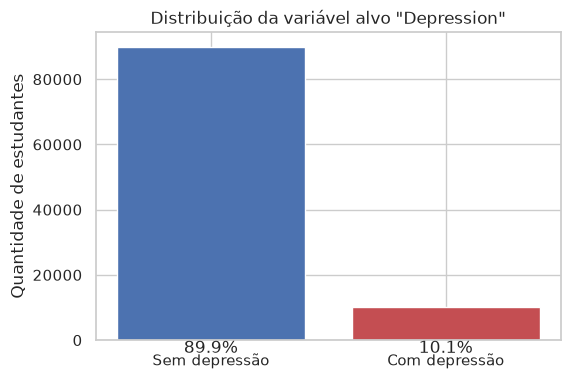

In [5]:
# Vamos criar contagem e porcentagem do total
counts = df['Depression'].value_counts()
pct = (100 * counts / len(df)).round(1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Sem depressão', 'Com depressão'], counts.values, color=['#4c72b0', '#c44e52'])
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, 0, f'{p}%', ha='center', va='top')    
ax.set_ylabel('Quantidade de estudantes')
ax.set_title('Distribuição da variável alvo "Depression"')
plt.show()

Apenas **~10% dos estudantes têm depressão**. Consequência direta: um modelo que previsse sempre "sem depressão" já alcançaria ~90% de accuracy. Por isso, além da accuracy, acompanharemos **recall, F1 e ROC-AUC** (seção 6) e cuidaremos do limiar de decisão.

### 3.3 Distribuições das variáveis numéricas

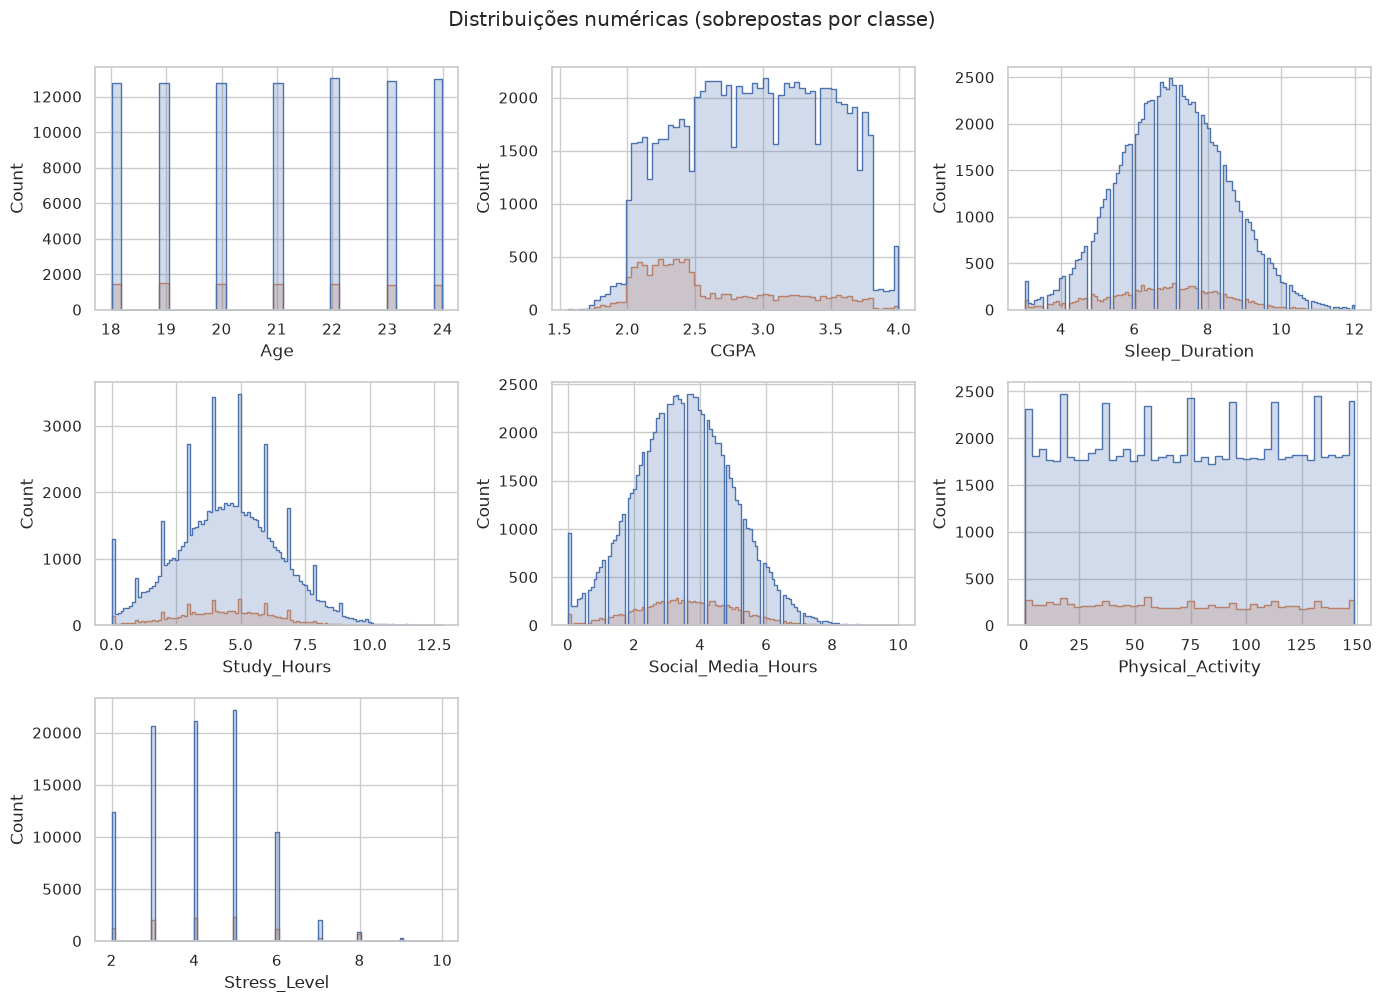

In [10]:
num_cols = ['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours',
            'Social_Media_Hours', 'Physical_Activity', 'Stress_Level']

# Vamos criar um grid 3x3 de gráficos
fig, axes = plt.subplots(3, 3, figsize=(14, 10))

# Para cada coluna, vamos pegar os dados da coluna alvo "Depression" e distribuir com os dados de cada coluna (Age, CGPA, etc)
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue='Depression', element='step', shrink=0.8, ax=ax, legend=False)    

# Não precisamos mostrar os dois últimos gráficos vazios (isso porque criamos um grid 3x3)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
    
plt.suptitle('Distribuições numéricas (sobrepostas por classe)', y=1.0)
plt.tight_layout()
plt.show()

Os padrões por classe são sutis: quem apresenta depressão tende a ter **CGPA um pouco menor**, **sono um pouco mais curto** e **estresse um pouco maior**, mas as distribuições se sobrepõem muito — nenhuma variável individual separa bem as classes, o que sugere um problema de sinal fraco e multivariado.

### 3.4 Variáveis categóricas e detalhamento de nível de estresse

Vamos analisar as variáveis que são categóricas (`Gender` e `Department`, ou seja, não possuem valores numéricos) e detalhar o nível de estresse (variável numérica que apresentou maior variabilidade de correlação).

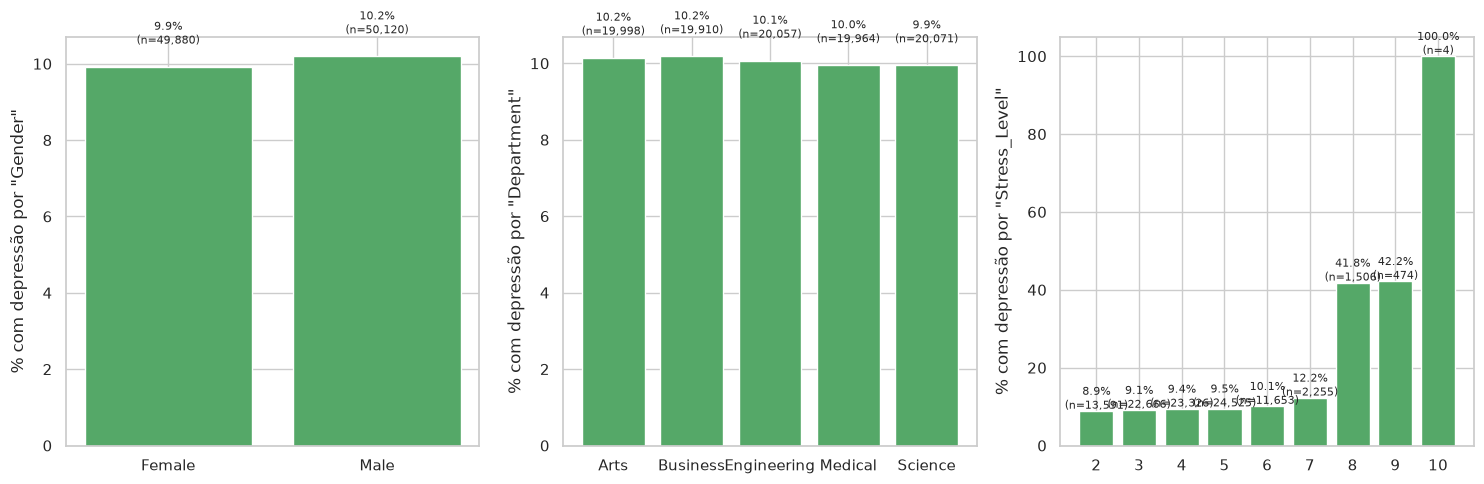

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, ['Gender', 'Department', 'Stress_Level']):
    g = df.groupby(col)['Depression'].agg(['mean', 'count'])
    ax.bar(g.index.astype(str), 100 * g['mean'], color='#55a868')
    for i, (m, c) in enumerate(zip(g['mean'], g['count'])):
        ax.text(i, 100 * m + 0.6, f'{100 * m:.1f}%\n(n={c:,})', ha='center', fontsize=8)    
    ax.set_ylabel(f'% com depressão por "{col}"')
plt.tight_layout()
plt.show()

**Gênero e departamento não trazem sinal** (~10% de depressão em todos os grupos). O destaque é **`Stress_Level`**: até o nível 7 a taxa fica em ~10%, mas **salta para ~42% nos níveis 8–9 e chega a 100% no nível 10** (apenas 4 registros). Esse salto é um sinal forte e **não-linear** — modelos lineares o captam mal; árvores de decisão, bem.

### 3.5 Análise de correlação

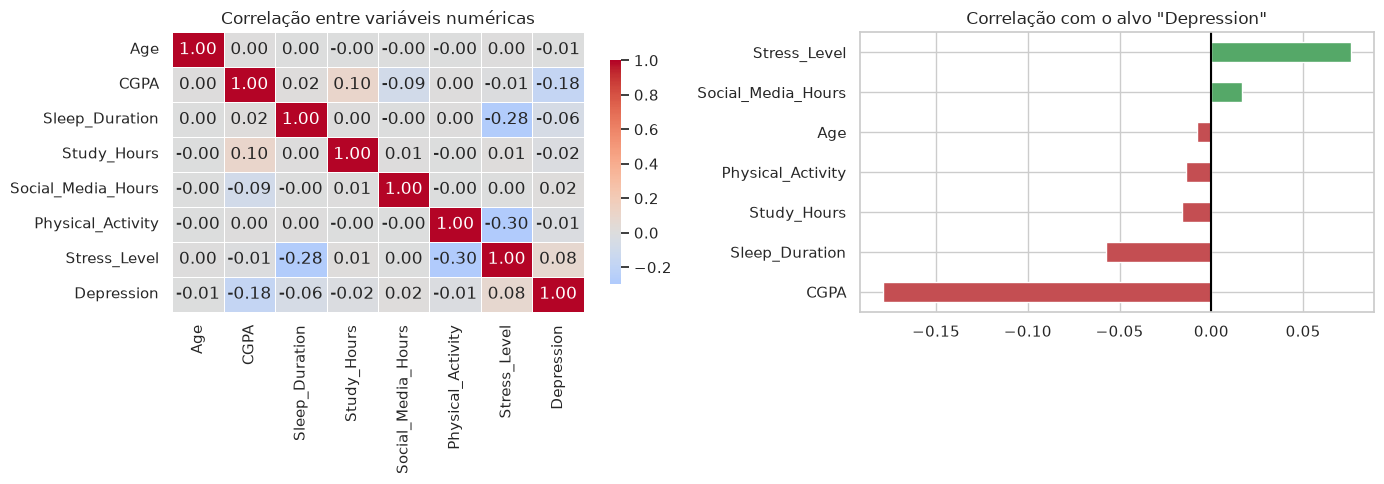

In [31]:
y = df['Depression'].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df[num_cols + ['Depression']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5, ax=axes[0], cbar_kws={'shrink': 0.8})
axes[0].set_title('Correlação entre variáveis numéricas')

corr_y = df[num_cols].corrwith(y).sort_values()
corr_y.plot(kind='barh', ax=axes[1], color=['#c44e52' if v < 0 else '#55a868' for v in corr_y.values])
axes[1].axvline(0, color='#000000')
axes[1].set_title('Correlação com o alvo "Depression"')
plt.tight_layout()
plt.show()

As correlações lineares com `Depression` são **fracas** (máx. |r| ≈ 0.18 para `CGPA` — menor desempenho acadêmico associado a mais depressão e em sequência `Stress_Level`). 

Entre as features, o único bloco relevante: `Stress_Level` correlaciona negativamente com `Sleep_Duration` (−0.28) e `Physical_Activity` (−0.30).

Atenção: `Stress_Level` tem r = 0.076 com o alvo, mas a seção 3.4 mostrou um salto forte nos níveis altos — **a correlação linear subestima essa relação não-linear**.

## 4. Limpeza dos dados

Antes de modelar, conferimos a qualidade da base: valores ausentes, duplicados e valores fora dos intervalos plausíveis de cada variável.

In [27]:
def checar_qualidade(d):
    print('Valores ausentes por coluna:')
    print(d.isna().sum().to_string())
    print(f"\nStudent_ID duplicados: {d['Student_ID'].duplicated().sum()}")
    print(f"Linhas 100% duplicadas: {d.duplicated().sum()}")
    limites = {'Age': (18, 30), 'CGPA': (0, 4), 'Sleep_Duration': (0, 24),
               'Study_Hours': (0, 24), 'Social_Media_Hours': (0, 24),
               'Physical_Activity': (0, 1440), 'Stress_Level': (1, 10)}
    for col, (lo, hi) in limites.items():
        n = ((d[col] < lo) | (d[col] > hi)).sum()
        print(f'{col}: {n} valores fora de [{lo}, {hi}]')

checar_qualidade(df)

Valores ausentes por coluna:
Student_ID            0
Age                   0
Gender                0
Department            0
CGPA                  0
Sleep_Duration        0
Study_Hours           0
Social_Media_Hours    0
Physical_Activity     0
Stress_Level          0
Depression            0

Student_ID duplicados: 0
Linhas 100% duplicadas: 0
Age: 0 valores fora de [18, 30]
CGPA: 0 valores fora de [0, 4]
Sleep_Duration: 0 valores fora de [0, 24]
Study_Hours: 0 valores fora de [0, 24]
Social_Media_Hours: 0 valores fora de [0, 24]
Physical_Activity: 0 valores fora de [0, 1440]
Stress_Level: 0 valores fora de [1, 10]


A base é **consistente**: sem valores ausentes, sem duplicados e sem valores fora de intervalo. A limpeza necessária é mínima:

1. Remover `Student_ID` — identificador, sem poder preditivo (usá-lo como feature seria ruído/vazamento);
2. Converter `Depression` de booleano para inteiro (0/1), formato adequado para modelagem.

In [28]:
df = df.drop(columns=['Student_ID'])
df['Depression'] = df['Depression'].astype(int)
df.head(3)

,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression
0,22,Female,Science,3.50,7.3,3.3,3.4,114,5,0
1,20,Male,Engineering,2.72,5.5,7.2,6.0,142,2,0
2,20,Male,Medical,3.01,5.4,2.3,1.8,137,3,0


## 5. Pré-processamento e divisão dos dados

**Regra de ouro contra vazamento (data leakage):** a divisão é feita **antes** de qualquer pré-processamento, e o pipeline (imputação + escala + one-hot) é ajustado **somente no treino** e aplicado, via `transform`, em validação e teste.

Divisão estratificada em **70% treino / 15% validação / 15% teste** — o teste será usado **uma única vez**, no final.

In [32]:
X = df.drop(columns=['Depression'])
y = df['Depression']

# Primeiro, separamos 70 e 30 para treino e o "resto"
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)

# Depois usamos os 30 restantes e separamos em 50 / 50. Assim, ficamos com 70 + 15 + 15 no estratificado.
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

for nome, Xs, ys in [('treino', X_tr, y_tr), ('validação', X_va, y_va), ('teste', X_te, y_te)]:
    print(f'{nome:>10}: {len(Xs):>6} linhas | % positivos: {ys.mean():.3f}')

    treino:  70000 linhas | % positivos: 0.101
 validação:  15000 linhas | % positivos: 0.101
     teste:  15000 linhas | % positivos: 0.101


In [33]:
num_cols = ['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours',
            'Social_Media_Hours', 'Physical_Activity', 'Stress_Level']
cat_cols = ['Gender', 'Department']


# Nosso pipeline de pré-processamento é importante para bases e dados futuros que não estejam tão limpos quanto os atuais.
# Para a nossa base de treino, validação e teste **não precisamos** de imputar dados como vimos acima.

def make_pre():
    """Pipeline de pré-processamento:
    - numéricas: imputação por mediana + escala padrão;
    - categóricas: imputação pela moda + one-hot encoding."""
    return ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), num_cols),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
    ])

## 6. Modelagem

Quatro técnicas de classificação, cada uma dentro do mesmo pipeline de pré-processamento:

|Modelo                 |Por quê                                                                |
|-----------------------|-----------------------------------------------------------------------|
|**Regressão Logística**|baseline linear, simples e interpretável;                              |
|**Árvore de Decisão**  |captura relações não-lineares (ex.: o salto de `Stress_Level` ≥ 8);    |
|**KNN**                |referência não-paramétrica, sensível à escala (daí o `StandardScaler`).|
|**Random Forest**    |ensemble de árvores — costuma superar uma árvore única e traz feature importance embutida;|

A busca de hiperparâmetros usa `GridSearchCV` com **5-fold estratificado** e `scoring='roc_auc'` (métrica robusta ao desbalanceamento). Incluímos `class_weight='balanced'` na grade para tratar o desbalanceamento de 10% de positivos. Antes de qualquer modelo, registramos a **baseline**: prever sempre a classe majoritária.

In [14]:
# Como já mencionamos, se forçacemos o resultado de dizer que SEMPRE o aluno não estará estressado, teremos uma acurácia alta pela distribuição dos dados.

baseline = max(y_tr.mean(), 1 - y_tr.mean())
print(f'Baseline (prever sempre a classe majoritária): accuracy = {baseline:.3f}')

Baseline (prever sempre a classe majoritária): accuracy = 0.899


In [34]:
# Para o tuning de hiper parâmetros vamos dividir a base em 5 partes ("folds") e executar um "grid search" (validar a acurácia de cada parâmetro).

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Como vimos, 4 modelos:
modelos = {
    'Regressão Logística': Pipeline([('pre', make_pre()), ('clf', LogisticRegression(max_iter=2000))]),
    'Árvore de Decisão':   Pipeline([('pre', make_pre()), ('clf', DecisionTreeClassifier())]),
    'KNN':                 Pipeline([('pre', make_pre()), ('clf', KNeighborsClassifier())]),
    'Random Forest':       Pipeline([('pre', make_pre()), ('clf', RandomForestClassifier())]),
}

# Parâmetros a testar:
grids = {
    'Regressão Logística': {
        'clf__C': [0.01, 0.1, 1, 10], 
        'clf__class_weight': [None, 'balanced']},
    'Árvore de Decisão': {
        'clf__max_depth': [3, 5, 10, None], 
        'clf__min_samples_leaf': [10, 50, 100], 
        'clf__class_weight': [None, 'balanced']},
    'KNN': {
        'clf__n_neighbors': [3, 5, 7, 9], 
        'clf__weights': ['uniform', 'distance']},
    'Random Forest': {
        'clf__n_estimators': [100, 300],
        'clf__max_depth': [5, 10, None],
        'clf__min_samples_leaf': [10, 50],
        'clf__class_weight': [None, 'balanced']},
}

# guarda os resultados das buscas de hiper-parâmetros
buscas = {}

for nome, pipe in modelos.items():
    gs = GridSearchCV(pipe, grids[nome], scoring='roc_auc', cv=cv, n_jobs=-1)
    gs.fit(X_tr, y_tr)
    buscas[nome] = gs
    print(f'{nome}: ROC-AUC (CV) = {gs.best_score_:.4f} | parâmetros: {gs.best_params_}')

Regressão Logística: ROC-AUC (CV) = 0.6855 | parâmetros: {'clf__C': 0.01, 'clf__class_weight': None}
Árvore de Decisão: ROC-AUC (CV) = 0.7024 | parâmetros: {'clf__class_weight': None, 'clf__max_depth': 5, 'clf__min_samples_leaf': 100}
KNN: ROC-AUC (CV) = 0.6130 | parâmetros: {'clf__n_neighbors': 9, 'clf__weights': 'distance'}
Random Forest: ROC-AUC (CV) = 0.7024 | parâmetros: {'clf__class_weight': 'balanced', 'clf__max_depth': 5, 'clf__min_samples_leaf': 10, 'clf__n_estimators': 300}


## 7. Treinamento e avaliação

Fluxo sem vazamento:
1. cada modelo é ajustado apenas no **treino** (hiperparâmetros já escolhidos por CV no treino);
2. o **melhor modelo** é escolhido pelo ROC-AUC na **validação**;
3. o **limiar de operação** é escolhido na **validação** (máximo de F1) — com 10% de positivos, o limiar padrão de 0.5 é muito conservador;
4. o **teste** é tocado uma única vez, no final.

In [16]:
pipes = {}
rows = []
for nome, gs in buscas.items():
    pipe = gs.best_estimator_
    # usando o melhor resultado da busca de hiper-parâmetros, executamos o treinamento
    pipe.fit(X_tr, y_tr)
    pipes[nome] = pipe
    prob = pipe.predict_proba(X_va)[:, 1]
    pred = (prob >= 0.5).astype(int)
    rows.append({'Modelo': nome,
                 'ROC-AUC': round(roc_auc_score(y_va, prob), 4),
                 'accuracy': round(accuracy_score(y_va, pred), 4),
                 'precision': round(precision_score(y_va, pred), 4),
                 'recall': round(recall_score(y_va, pred), 4),
                 'F1': round(f1_score(y_va, pred), 4)})
m_va = pd.DataFrame(rows).set_index('Modelo')
print(m_va)

melhor = m_va['ROC-AUC'].idxmax()
print(f'\nMelhor modelo (ROC-AUC em validação): {melhor}')

                     ROC-AUC  accuracy  precision  recall      F1
Modelo                                                           
Regressão Logística   0.6837    0.8993     0.0000  0.0000  0.0000
Árvore de Decisão     0.6985    0.8994     0.5079  0.0212  0.0407
KNN                   0.6196    0.8961     0.2870  0.0219  0.0406
Random Forest         0.6953    0.7324     0.2160  0.6305  0.3217

Melhor modelo (ROC-AUC em validação): Árvore de Decisão


In [17]:
limiares = {}
for nome, pipe in pipes.items():
    prob = pipe.predict_proba(X_va)[:, 1]
    fpr, tpr, thr = roc_curve(y_va, prob)
    f1s = np.array([f1_score(y_va, (prob >= t).astype(int)) for t in thr])
    limiares[nome] = thr[int(np.argmax(f1s))]
print('Limiar ótimo para F1 (escolhido na validação):')
for nome, t in limiares.items():
    print(f'  {nome}: {t:.3f}')

Limiar ótimo para F1 (escolhido na validação):
  Regressão Logística: 0.131
  Árvore de Decisão: 0.105
  KNN: 0.140
  Random Forest: 0.482


In [18]:
pipe_final = pipes[melhor]
thr = limiares[melhor]
prob_te = pipe_final.predict_proba(X_te)[:, 1]

print(f'=== {melhor} — TESTE, limiar padrão (0.5) ===')
print(classification_report(y_te, (prob_te >= 0.5).astype(int)))
print(f'=== {melhor} — TESTE, limiar de operação ({thr:.3f}, escolhido na validação) ===')
print(classification_report(y_te, (prob_te >= thr).astype(int)))
print('Matriz de confusão (limiar de operação):')
print(confusion_matrix(y_te, (prob_te >= thr).astype(int)))

=== Árvore de Decisão — TESTE, limiar padrão (0.5) ===
              precision    recall  f1-score   support

           0       0.90      1.00      0.95     13491
           1       0.54      0.02      0.04      1509

    accuracy                           0.90     15000
   macro avg       0.72      0.51      0.49     15000
weighted avg       0.87      0.90      0.86     15000

=== Árvore de Decisão — TESTE, limiar de operação (0.105, escolhido na validação) ===
              precision    recall  f1-score   support

           0       0.95      0.74      0.83     13491
           1       0.22      0.66      0.33      1509

    accuracy                           0.73     15000
   macro avg       0.59      0.70      0.58     15000
weighted avg       0.88      0.73      0.78     15000

Matriz de confusão (limiar de operação):
[[10001  3490]
 [  520   989]]


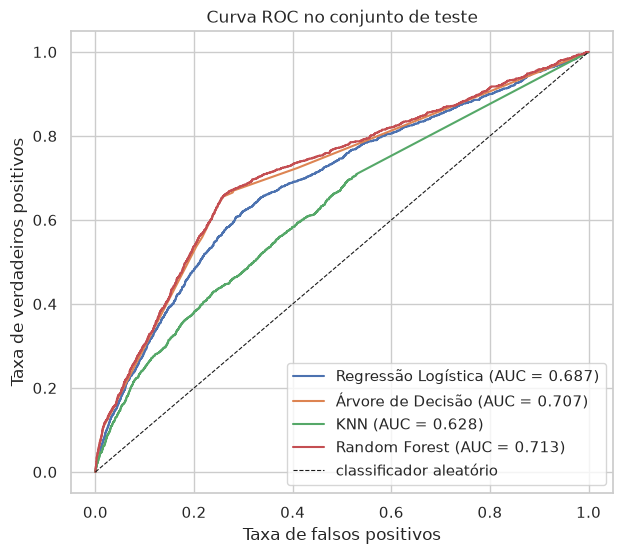

In [19]:
plt.figure(figsize=(7, 6))
for nome, pipe in pipes.items():
    prob = pipe.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, prob)
    plt.plot(fpr, tpr, label=f'{nome} (AUC = {roc_auc_score(y_te, prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=0.8, label='classificador aleatório')
plt.xlabel('Taxa de falsos positivos')
plt.ylabel('Taxa de verdadeiros positivos')
plt.title('Curva ROC no conjunto de teste')
plt.legend()
plt.show()

**Escolha da métrica e leitura dos resultados.** No limiar padrão (0.5), a accuracy (~0.90) é enganosa: ela é idêntica à baseline e esconde um **recall quase nulo** — o modelo praticamente não identifica quem tem depressão. Isso é o desbalanceamento agindo: com 90% de negativos, o limiar 0.5 é excessivamente conservador.

No limiar de operação (escolhido para maximizar F1 na validação), a Árvore de Decisão recupera a maioria dos casos de depressão (recall alto) com precisão moderada. Em contexto clínico, **o recall (sensibilidade) costuma pesar mais**: um falso negativo adia o cuidado de quem precisa; um falso positivo apenas gera uma entrevista a mais. O limiar final deve ser ajustado pela equipe clínica conforme o custo relativo de cada erro — a curva ROC acima mostra todo o espectro de trade-offs disponível.

### Análise de erros

Avaliação aprofundada do modelo vencedor, sempre no conjunto de teste:

- **Curva Precision–Recall**: mais informativa que a ROC para classes desbalanceadas — mostra o trade-off diretamente na classe positiva;
- **Calibração**: uma probabilidade prevista de 0,3 realmente corresponde a ~30% de casos com depressão?
- **Varredura de limiar**: como accuracy, precision, recall e F1 mudam com o limiar de decisão;
- **Recall/precision por faixa de estresse**: em que perfis o modelo falha;
- **Perfil dos erros**: características médias de TP, TN, FP e FN.

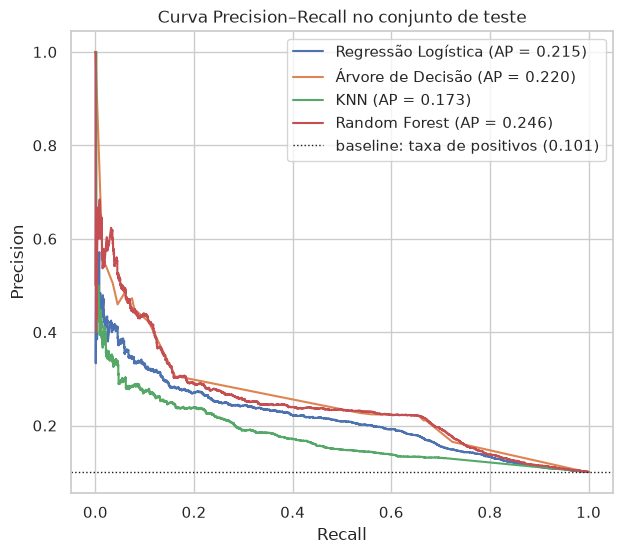

In [20]:
plt.figure(figsize=(7, 6))
for nome, pipe in pipes.items():
    prob = pipe.predict_proba(X_te)[:, 1]
    prec, rec, _ = precision_recall_curve(y_te, prob)
    plt.plot(rec, prec, label=f'{nome} (AP = {average_precision_score(y_te, prob):.3f})')
plt.axhline(y_te.mean(), color='k', ls=':', lw=1,
            label=f'baseline: taxa de positivos ({y_te.mean():.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision–Recall no conjunto de teste')
plt.legend()
plt.show()

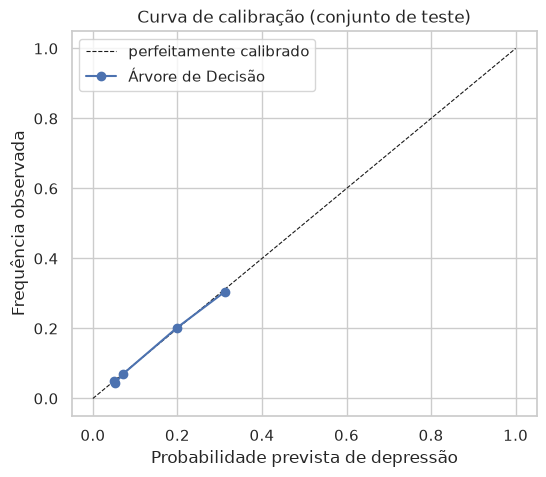

In [21]:
prob = pipes[melhor].predict_proba(X_te)[:, 1]
frac, mean_pred = calibration_curve(y_te, prob, n_bins=10, strategy='quantile')

plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], 'k--', lw=0.8, label='perfeitamente calibrado')
plt.plot(mean_pred, frac, 'o-', color='#4c72b0', label=melhor)
plt.xlabel('Probabilidade prevista de depressão')
plt.ylabel('Frequência observada')
plt.title('Curva de calibração (conjunto de teste)')
plt.legend()
plt.show()

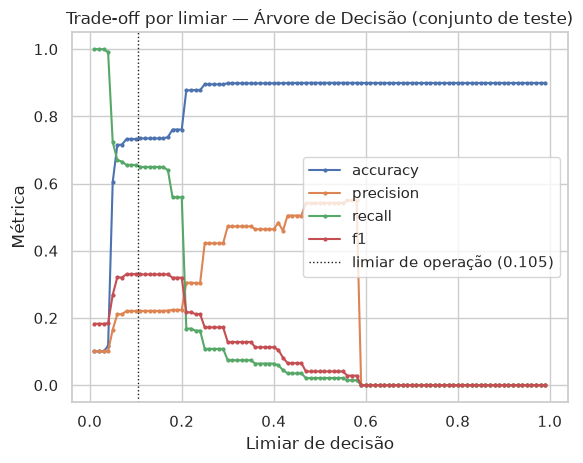

In [22]:
thr_grid = np.linspace(0.01, 0.99, 99)
linhas = []
for t in thr_grid:
    pred = (prob >= t).astype(int)
    linhas.append({'limiar': t,
                   'accuracy': accuracy_score(y_te, pred),
                   'precision': precision_score(y_te, pred, zero_division=0),
                   'recall': recall_score(y_te, pred),
                   'f1': f1_score(y_te, pred)})
df_thr = pd.DataFrame(linhas)

df_thr.plot(x='limiar', y=['accuracy', 'precision', 'recall', 'f1'], marker='o', ms=2)
plt.axvline(limiares[melhor], color='k', ls=':', lw=1,
            label=f'limiar de operação ({limiares[melhor]:.3f})')
plt.xlabel('Limiar de decisão')
plt.ylabel('Métrica')
plt.title(f'Trade-off por limiar — {melhor} (conjunto de teste)')
plt.legend()
plt.show()

In [23]:
pred_te = (prob >= limiares[melhor]).astype(int)
df_err = X_te.copy()
df_err['y'] = y_te.values
df_err['pred'] = pred_te

faixa = pd.cut(df_err['Stress_Level'], bins=[1, 5, 7, 10], labels=['2–5', '6–7', '8–10'])
g = df_err.assign(faixa=faixa).groupby('faixa', observed=True)
tabela = pd.DataFrame({
    'n': g.size(),
    'positivos': g.apply(lambda s: int(s['y'].sum()), include_groups=False),
    'recall': g.apply(lambda s: s.loc[s['y'] == 1, 'pred'].mean() if (s['y'] == 1).any() else np.nan,
                      include_groups=False),
    'precision': g.apply(lambda s: s.loc[s['pred'] == 1, 'y'].mean() if (s['pred'] == 1).any() else np.nan,
                         include_groups=False),
}).round(3)
print(f'Recall e precision por faixa de estresse — {melhor} (limiar {limiares[melhor]:.3f}):')
tabela

Recall e precision por faixa de estresse — Árvore de Decisão (limiar 0.105):


,n,positivos,recall,precision
faixa,,,,
2–5,12544,1142,0.620,0.205
6–7,2126,226,0.619,0.202
8–10,330,141,1.000,0.427


In [24]:
rotulos = np.select(
    [(df_err['y'] == 1) & (df_err['pred'] == 1),
     (df_err['y'] == 1) & (df_err['pred'] == 0),
     (df_err['y'] == 0) & (df_err['pred'] == 1)],
    ['TP — depressão identificada',
     'FN — depressão NÃO identificada',
     'FP — falso alarme'],
    default='TN — sem depressão, corretamente')
df_grp = df_err.assign(grupo=rotulos)
perfil = df_grp.groupby('grupo')[num_cols].mean()
perfil['n'] = df_grp.groupby('grupo').size()
perfil.sort_values('n', ascending=False)

,Age,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,n
grupo,,,,,,,,
"TN — sem depressão, corretamente",20.985801,3.150333,7.098890,4.578592,3.443336,75.143586,4.029997,10001
FP — falso alarme,21.004298,2.298476,6.846447,4.301977,3.672464,72.549857,4.340401,3490
TP — depressão identificada,20.918099,2.321264,6.464206,4.350051,3.602224,71.425683,4.737108,989
FN — depressão NÃO identificada,20.886538,3.191769,6.991346,4.720192,3.446538,72.571154,4.123077,520


**Leitura da análise de erros.** O comportamento é consistente entre as faixas de estresse: recall ≈ 0,62 nas faixas baixa/média (2–7) e **recall = 1,00 na faixa alta (8–10)**, onde o sinal é forte — mas a precision cai para 0,43 (muitos falsos alarmes nessa faixa, que concentra os casos mais graves).

O perfil dos erros é mais revelador que as métricas globais: **os falsos negativos (FN) têm perfil de estilo de vida praticamente idêntico ao grupo "sem depressão" classificado corretamente** (CGPA 3,19 × 3,15; estresse 4,1 × 4,0) — são estudantes com depressão cujos dados simplesmente não exibem sinais de risco, e nenhum modelo baseado nessas features os identificaria. **Os falsos positivos (FP)** são puxados principalmente por CGPA baixo (2,30): o modelo "exagera" a reação ao desempenho acadêmico ruim.

Ou seja: o erro do modelo não é questão de tuning — reflete o limite dos dados. Na prática, a lista de "alto risco" deve ser tratada como ponto de partida para entrevista humana, não como triagem definitiva.

## 8. Interpretação dos resultados

Duas técnicas complementares para entender **por que** o modelo decide como decide:

- **Permutation importance** (agnóstico ao modelo): quanto o ROC-AUC cai quando cada feature é embaralhada;
- **SHAP** (Kernel SHAP): contribuição de cada feature na decisão de cada indivíduo — essencial para confiança em aplicações clínicas.

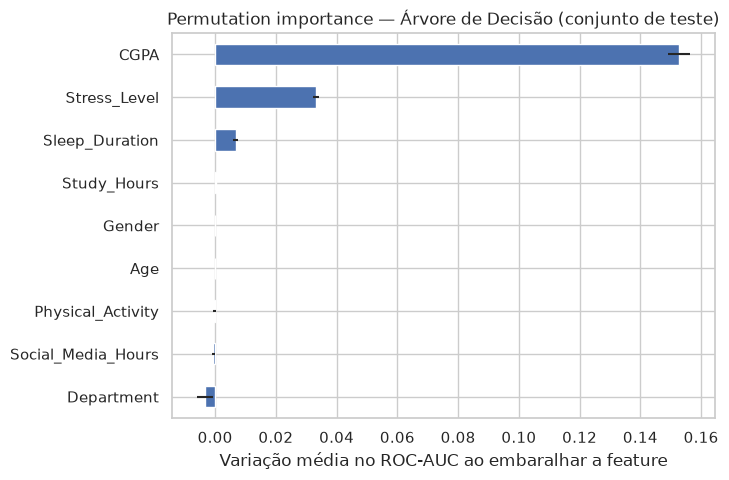

,media,std
Department,-0.003348,0.002674
Social_Media_Hours,-0.000615,0.000539
Physical_Activity,-0.000313,0.000437
Age,-0.000067,0.000020
Gender,0.000000,0.000000
Study_Hours,0.000277,0.000124
Sleep_Duration,0.006767,0.000810
Stress_Level,0.033198,0.001144
CGPA,0.152670,0.003672


In [25]:
res = permutation_importance(pipes[melhor], X_te, y_te, n_repeats=5, random_state=SEED,
                             scoring='roc_auc', n_jobs=-1)
imp = pd.DataFrame({'media': res.importances_mean, 'std': res.importances_std},
                   index=list(X_te.columns)).sort_values('media')

plt.figure(figsize=(7, 5))
imp['media'].plot(kind='barh', xerr=imp['std'], color='#4c72b0')
plt.xlabel('Variação média no ROC-AUC ao embaralhar a feature')
plt.title(f'Permutation importance — {melhor} (conjunto de teste)')
plt.show()
imp

  0%|          | 0/300 [00:00<?, ?it/s]

  1%|▏         | 4/300 [00:00<00:07, 39.84it/s]

  3%|▎         | 9/300 [00:00<00:07, 40.98it/s]

  5%|▍         | 14/300 [00:00<00:06, 40.99it/s]

  6%|▋         | 19/300 [00:00<00:06, 40.88it/s]

...

 95%|█████████▍| 284/300 [00:06<00:00, 40.99it/s]

 96%|█████████▋| 289/300 [00:07<00:00, 40.97it/s]

 98%|█████████▊| 294/300 [00:07<00:00, 41.09it/s]

100%|█████████▉| 299/300 [00:07<00:00, 41.19it/s]

100%|██████████| 300/300 [00:07<00:00, 40.74it/s]

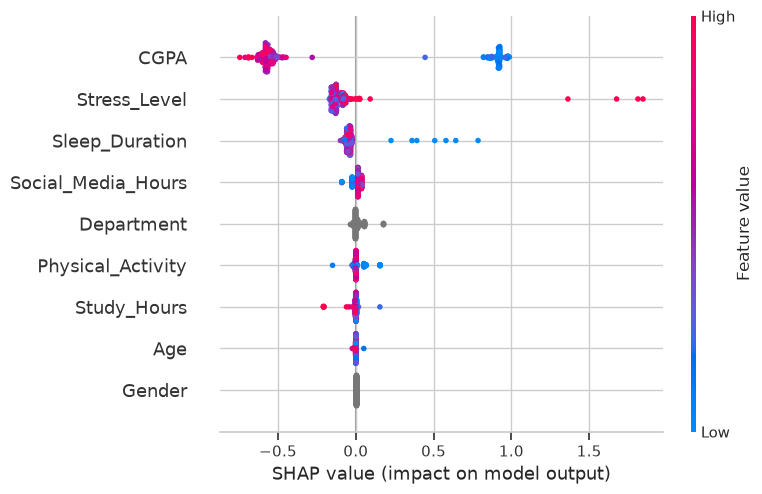

In [26]:
cols = list(X.columns)
modelo_fn = lambda X: pipes[melhor].predict_proba(pd.DataFrame(X, columns=cols))[:, 1]

background = X_tr.sample(100, random_state=SEED)   # base de referência (treino)
amostra = X_te.sample(300, random_state=SEED)      # amostra do teste para explicar

explainer = shap.KernelExplainer(modelo_fn, background, link='logit')
shap_values = np.asarray(explainer.shap_values(amostra))

shap.summary_plot(shap_values, amostra, show=False)
plt.show()

`CGPA` e `Stress_Level` dominam a decisão — coerente com a EDA: CGPA é a correlação linear mais forte com o alvo, e Stress_Level tem o salto não-linear nos níveis 8–10. Sono, estudo e atividade física aparecem como fatores secundários. SHAP mostra também a **direção** de cada contribuição (ex.: CGPA baixo e estresse alto empurram para "depressão"), o que torna a decisão auditável por um profissional de saúde.

## 9. Conclusão e discussão crítica

**O que foi construído.** Um pipeline completo e reproduzível (seeds fixas, split 70/15/15 estratificado, CV 5-fold, pré-processamento ajustado só no treino) que classifica a probabilidade de depressão a partir de 9 features de estilo de vida. Quatro modelos foram comparados; a **Árvore de Decisão** venceu (ROC-AUC 0,699 em validação; 0,707 no teste), à frente do Random Forest (0,698) — o ensemble não superou a árvore única bem regularizada (`max_depth=5`, `min_samples_leaf=100`), coerente com um sinal fraco e parcialmente não-linear.

**O modelo pode ser usado na prática? Como?**
- **Sim, como ferramenta de triagem — não como diagnóstico.** O papel do sistema é priorizar a fila: sinalizar os estudantes de maior risco para entrevista psicológica, reduzindo o tempo de triagem e destacando as informações relevantes (SHAP) para o profissional.
- **O médico/psicólogo sempre tem a palavra final.** O modelo reduz trabalho, não substitui julgamento clínico: diagnóstico de depressão exige avaliação profissional (anamnese, questionários validados como PHQ-9, histórico).
- **Limitações a declarar:** (i) sinal fraco — ROC-AUC ≈ 0.71, e o dataset é sintético, sem variáveis clínicas reais; (ii) correlação não implica causalidade; (iii) o desbalanceamento (10%) exige escolha consciente do limiar; (iv) subgrupos raros (ex.: `Stress_Level = 10`, 4 registros) têm estimativas instáveis.
- **Próximos passos:** incluir variáveis clínicas, comparar com ensemble (Random Forest/GBM), calibração de probabilidades e validação em dados de outra fonte antes de qualquer uso real.